# Formula 1 Document Q&A RAG System

##  1. Web Scraping Formula 1 Wikipedia Articles

We scrape 10 core Wikipedia pages covering F1 history, cars, drivers (Lewis Hamilton, Max Verstappen), iconic teams (Ferrari, Mercedes), regulations, and circuits (Monaco GP).

**Cleaning Requirements:**
- Target main content area (`div id="mw-content-text"`)
- Strip HTML tags, reference links (`[1]`, `[2]`), edit tags (`[edit]`), and navboxes
- Retain section titles prefixed with `## ` to preserve document hierarchy
- Export each article to `.txt` files in `scraped_pages/`


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure local module directory is in python path
sys.path.append(os.path.abspath("."))

from scraper import scrape_pages, DEFAULT_WIKIPEDIA_URLS
from chunker import chunk_all_documents, chunk_document
from rag import RAGSystem

# Run Web Scraper across all 10 Wikipedia pages
scraped_data = scrape_pages(output_dir="scraped_pages")

# Display Character Counts per Scraped Page
stats = []
for page_name, text in scraped_data.items():
    stats.append({
        "Page Filename": page_name,
        "Character Count": len(text),
        "Estimated Word Count": len(text.split()),
        "Section Headers Count": text.count("## ")
    })

df_scraping = pd.DataFrame(stats).sort_values(by="Character Count", ascending=False)
display(df_scraping)


/Users/badrootz/eVantage/sapt6/rag_system/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- STEP 1: Starting Web Scraping (10 pages) ---
  ✓ Extracted 118,350 characters -> Formula_One.txt (https://en.wikipedia.org/wiki/Formula_One)
  ✓ Extracted 102,080 characters -> History_of_Formula_One.txt (https://en.wikipedia.org/wiki/History_of_Formula_One)
  ✓ Extracted 36,810 characters -> Formula_One_car.txt (https://en.wikipedia.org/wiki/Formula_One_car)
  ✓ Extracted 174,063 characters -> Lewis_Hamilton.txt (https://en.wikipedia.org/wiki/Lewis_Hamilton)
  ✓ Extracted 161,093 characters -> Max_Verstappen.txt (https://en.wikipedia.org/wiki/Max_Verstappen)
  ✓ Extracted 42,075 characters -> Scuderia_Ferrari.txt (https://en.wikipedia.org/wiki/Scuderia_Ferrari)
  ✓ Extracted 45,321 characters -> Mercedes-Benz_in_Formula_One.txt (https://en.wikipedia.org/wiki/Mercedes-Benz_in_Formula_One)
  ✓ Extracted 15,123 characters -> List_of_Formula_One_World_Drivers__Champions.txt (https://en.wikipedia.org/wiki/List_of_Formula_One_World_Drivers%27_Champions)
  ✓ Extracted 49,260 characters -

,Page Filename,Character Count,Estimated Word Count,Section Headers Count
3,Lewis_Hamilton.txt,174063,27999,60
4,Max_Verstappen.txt,161093,26234,51
0,Formula_One.txt,118350,19222,33
1,History_of_Formula_One.txt,102080,16820,22
8,Monaco_Grand_Prix.txt,49260,8279,25
6,Mercedes-Benz_in_Formula_One.txt,45321,7250,19
5,Scuderia_Ferrari.txt,42075,6819,22
2,Formula_One_car.txt,36810,6246,12
9,Formula_One_regulations.txt,35820,6058,19
7,List_of_Formula_One_World_Drivers__Champions.txt,15123,2458,11


##  2. Text Chunking & Chunk Size Experimentation

Text chunking divides long articles into digestible segments for embedding models. We implement a **sliding window chunker** defined by:
- `chunk_size`: target number of tokens per chunk (approximated via `len(text.split())`)
- `overlap`: number of tokens carried over from the previous chunk to maintain context continuity across boundaries.

Each chunk retains metadata: `chunk_id`, `source_page`, `chunk_text`, and `char_start`.

### Chunk Size Experimentation
We evaluate 3 chunking configurations:
1. **Small:** `chunk_size = 200`, `overlap = 50`
2. **Medium:** `chunk_size = 500`, `overlap = 100`
3. **Large:** `chunk_size = 1000`, `overlap = 200`

We run retrieval quality tests on 3 specific domain questions:
- *Q1: "In what year did Formula 1 hold its first official World Championship season?"*
- *Q2: "What are the key technical aerodynamic components of a modern Formula One car?"*
- *Q3: "Which driver holds the record for most Formula One World Championship titles?"*


In [2]:
configs = [
    {"name": "Small", "chunk_size": 200, "overlap": 50},
    {"name": "Medium", "chunk_size": 500, "overlap": 100},
    {"name": "Large", "chunk_size": 1000, "overlap": 200},
]

exp_summary = []
test_queries = [
    "In what year did Formula 1 hold its first official World Championship season?",
    "What are the key technical aerodynamic components of a modern Formula One car?",
    "Which driver holds the record for most Formula One World Championship titles?"
]

for cfg in configs:
    # Build or load index for specific configuration
    cache_path = f"chunks_cache_{cfg['name'].lower()}.pkl"
    rag_exp = RAGSystem(
        chunk_size=cfg["chunk_size"],
        overlap=cfg["overlap"],
        cache_file=cache_path,
        scraped_pages_dir="scraped_pages",
        force_reindex=True
    )
    
    total_chunks = len(rag_exp.chunks)
    avg_char_len = int(np.mean([c["char_length"] for c in rag_exp.chunks]))
    
    sim_scores = []
    for q in test_queries:
        top_res = rag_exp.retrieve(q, k=1)[0]
        sim_scores.append(top_res["similarity_score"])
        
    exp_summary.append({
        "Configuration": cfg["name"],
        "Chunk Size (tokens)": cfg["chunk_size"],
        "Overlap (tokens)": cfg["overlap"],
        "Total Chunks Generated": total_chunks,
        "Avg Chunk Length (chars)": avg_char_len,
        "Avg Top-1 Sim Score": round(float(np.mean(sim_scores)), 4)
    })

df_exp = pd.DataFrame(exp_summary)
display(df_exp)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12949.26it/s]


,Configuration,Chunk Size (tokens),Overlap (tokens),Total Chunks Generated,Avg Chunk Length (chars),Avg Top-1 Sim Score
0,Small,200,50,851,1217,0.7033
1,Medium,500,100,319,3037,0.6782
2,Large,1000,200,161,5991,0.6782




We use `sentence-transformers` with model `all-MiniLM-L6-v2` to transform raw text into 384-dimensional dense vectors.
- Embeddings are generated once and cached in `chunks_with_embeddings.pkl`.
- On startup, the system loads existing cached embeddings automatically.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16065.95it/s]


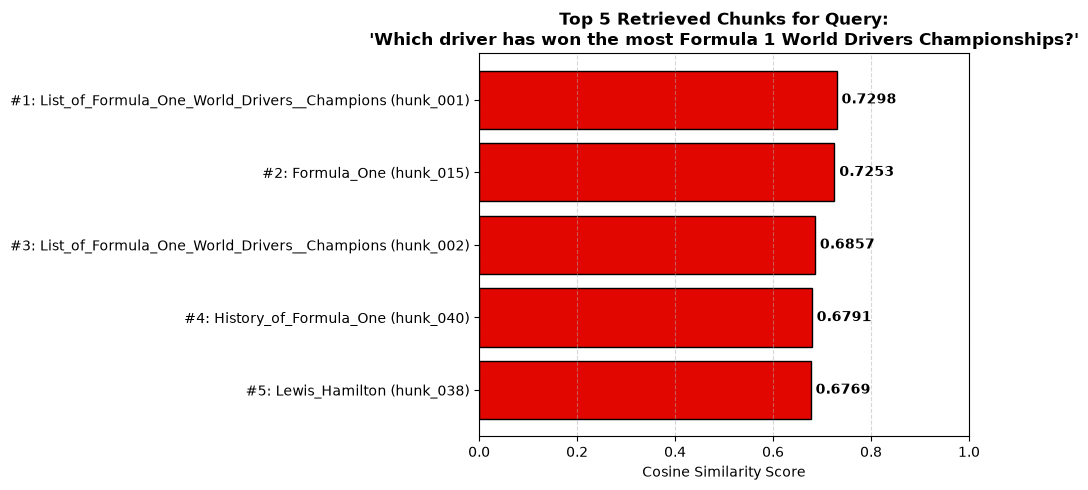

In [3]:
# Initialize default RAG System (Medium size: 500 / 100)
rag_main = RAGSystem(chunk_size=500, overlap=100, cache_file="chunks_with_embeddings.pkl", scraped_pages_dir="scraped_pages")

sample_query = "Which driver has won the most Formula 1 World Drivers Championships?"
retrieved_5 = rag_main.retrieve(sample_query, k=5)

# Plot top 5 retrieved chunks with similarity scores as a horizontal bar chart
plt.figure(figsize=(10, 5))
labels = [f"#{i+1}: {c['source_page'].replace('.txt', '')} ({c['chunk_id'][-8:]})" for i, c in enumerate(retrieved_5)]
scores = [c['similarity_score'] for c in retrieved_5]

bars = plt.barh(labels[::-1], scores[::-1], color='#e10600', edgecolor='black')
plt.xlabel('Cosine Similarity Score')
plt.title(f"Top 5 Retrieved Chunks for Query:\n'{sample_query}'", fontsize=12, fontweight='bold')
plt.xlim(0, 1.0)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f"{width:.4f}", va='center', fontweight='bold')

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 3. Full RAG Pipeline Demo

We demonstrate `retrieve(query, k=5)` combined with `generate_response(query, chunks)` powered by **Gemini**.

A 2-second rate-limit sleep (`time.sleep(2.0)`) is executed between API calls.

### Demonstration on 5 Domain Questions:


In [4]:
demo_questions = [
    "What is the history and significance of the Monaco Grand Prix in Formula 1?",
    "How many World Championships has Lewis Hamilton won and with which teams?",
    "What aerodynamic principles govern ground effect in modern Formula One cars?",
    "What are the main financial and engine power unit regulations introduced in modern F1?",
    "What team did Max Verstappen debut for in Formula 1 and when did he win his first race?"
]

for idx, q in enumerate(demo_questions, 1):
    print("=" * 80)
    print(f"DEMO QUESTION #{idx}: {q}")
    print("=" * 80)
    
    top_chunks = rag_main.retrieve(q, k=3)
    print("Top Retrieved Sources:")
    for c in top_chunks:
        print(f"  • [{c['similarity_score']:.4f}] {c['source_page']} ({c['chunk_id']})")
        
    answer = rag_main.generate_response(q, top_chunks, enforce_grounding=True)
    print("\nGemini:")
    print(answer)
    print("\n\n")


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


DEMO QUESTION #1: What is the history and significance of the Monaco Grand Prix in Formula 1?
Top Retrieved Sources:
  • [0.7330] Monaco_Grand_Prix.txt (Monaco_Grand_Prix_chunk_001)
  • [0.6862] Monaco_Grand_Prix.txt (Monaco_Grand_Prix_chunk_016)
  • [0.6704] Monaco_Grand_Prix.txt (Monaco_Grand_Prix_chunk_015)

Gemini:
The Monaco Grand Prix is widely considered one of the most prestigious and important automobile races in the world and is part of the Triple Crown of Motorsport, alongside the 24 Hours of Le Mans and the Indianapolis 500. It is described as "an exceptional location of glamour and prestige" and is one of the most demanding circuits in Formula One due to its narrow street course, tight corners, elevation changes, and a tunnel. Notably, it is the only Grand Prix that does not adhere to the FIA's mandated minimum race distance of 305 kilometres (190 miles).

**History**
The event was organized in 1929 by Antony Noghès under the auspices of Prince Louis II through the Automob

##  4. Failure Case Analysis

RAG systems fail under predictable conditions such as temporal recency mismatches, cross-page reasoning requirement, or dense numerical retrieval.

We evaluate the system on **3 intentionally difficult questions**:
1. *"Who won the 2023 Formula 1 World Championship?"* (Recency / Scraped Data boundaries)
2. *"What is the tire degradation strategy at Monaco compared to Silverstone?"* (Cross-page multi-hop reasoning)
3. *"How many points did Hamilton score in his worst season?"* (Dense numerical retrieval across multi-year stats)


In [5]:
difficult_questions = [
    {
        "id": 1,
        "title": "Recency Mismatch Test",
        "query": "Who won the 2023 Formula 1 World Championship?"
    },
    {
        "id": 2,
        "title": "Cross-Page Reasoning Test",
        "query": "What is the tire degradation strategy at Monaco compared to Silverstone?"
    },
    {
        "id": 3,
        "title": "Precise Numerical Retrieval Test",
        "query": "How many points did Hamilton score in his worst season?"
    }
]

for item in difficult_questions:
    q = item["query"]
    print(f"--- FAILURE CASE #{item['id']}: {item['title']} ---")
    print(f"Query: '{q}'\n")
    
    chunks = rag_main.retrieve(q, k=4)
    print("Retrieved Chunks:")
    for c in chunks:
        print(f"  - [{c['similarity_score']:.4f}] {c['source_page']}: {c['chunk_text'][:150]}...")
        
    ans = rag_main.generate_response(q, chunks, enforce_grounding=True, model_name="gemma-4-31b-it")
    print("\nGenerated Answer:")
    print(ans)
    print("\n" + "=" * 80 + "\n")
    import time
    time.sleep(12.5)





--- FAILURE CASE #1: Recency Mismatch Test ---
Query: 'Who won the 2023 Formula 1 World Championship?'

Retrieved Chunks:
  - [0.6082] List_of_Formula_One_World_Drivers__Champions.txt: The World Drivers' Championship is presented by the Fédération Internationale de l'Automobile (FIA), motorsport's world governing body, to the most su...
  - [0.5990] Formula_One.txt: As teams kept their numbers for long periods of time, car numbers became associated with a team, such as Ferrari's 27 and 28. A different system was u...
  - [0.5945] Monaco_Grand_Prix.txt: ## Criticism

In the 21st century, several commentators and F1 drivers have called the Grand Prix the most boring race of all circuits, both to drive ...
  - [0.5910] History_of_Formula_One.txt: Stuart, Greg. "10 things you need to know about the all-new 2022 F1 car". Formula 1. Retrieved 7 March 2023.
↑ "F1's 2021 rule changes: 10 things you ...



Generated Answer:
Max Verstappen won the 2023 title.




--- FAILURE CASE #2: Cross-Page Reasoning Test ---
Query: 'What is the tire degradation strategy at Monaco compared to Silverstone?'

Retrieved Chunks:
  - [0.5092] Monaco_Grand_Prix.txt: The Monaco Grand Prix (French: Grand Prix de Monaco) is a Formula One motor racing event held annually on the Circuit de Monaco, in late May or early ...
  - [0.4972] Monaco_Grand_Prix.txt: December 2020.
↑ Hughes, Mark (2021). "Cracked wheel hub to blame for Leclerc missing Monaco race". The Race. Archived from the original on 4 August 2...
  - [0.4887] List_of_Formula_One_World_Drivers__Champions.txt: indicate championships won as the sole tyre supplier.

↑ Goodyear was the sole tyre supplier for the 1987, 1988 and 1992-1996 seasons.
↑ Pirelli has b...
  - [0.4882] Monaco_Grand_Prix.txt: 2003). "The cradle of motorsport". www.forix.com. Archived from the original on 20 February 2007. Retrieved 29 November 2025.
1 2 "History". Retrieved...



Generated Answer:
I don't have enough information in my knowledge base to answer this.




--- FAILURE CASE #3: Precise Numerical Retrieval Test ---
Query: 'How many points did Hamilton score in his worst season?'

Retrieved Chunks:
  - [0.5732] Lewis_Hamilton.txt: extension with Mercedes, reported to be worth up to £40 million per year, making him the best-paid Formula One driver in history.

Hamilton led the ch...
  - [0.5166] Lewis_Hamilton.txt: 12-point advantage in the standings evanesced. He finished runner-up in the championship to Räikkönen by one point, classified ahead of teammate Alons...
  - [0.5084] Lewis_Hamilton.txt: only pole position of the season, and took the championship lead after winning the race. Hamilton's latter half of the season unravelled with a number...
  - [0.4940] Lewis_Hamilton.txt: unexpected driver transfers in Formula One history, and marked the first time in his career where he did not drive for a Mercedes-powered team. His di...



Generated Answer:
I don't have enough information in my knowledge base to answer this.




## 5. Hallucination Example

To illustrate the critical role of RAG prompt constraints, we ask an out-of-domain question that is **NOT** present in any scraped Wikipedia page:

*"What was the catering menu at the 2019 Monaco Grand Prix paddock?"*

We compare:
1. **With Grounding Instruction:** Asking Gemini using the strict RAG context template.
2. **Without Grounding Instruction:** Removing context boundaries and letting the model generate freely.


In [5]:
out_of_domain_query = "What was the catering menu at the 2019 Monaco Grand Prix paddock?"

retrieved_ood = rag_main.retrieve(out_of_domain_query, k=3)

print(f"Out-of-Domain Query: '{out_of_domain_query}'\n")
print("Top Retrieved Chunks (Low Similarity Scores):")
for c in retrieved_ood:
    print(f"  • [{c['similarity_score']:.4f}] {c['source_page']} ({c['chunk_id']})")
print("\n" + "=" * 80)

# 1. WITH GROUNDING
ans_grounded = rag_main.generate_response(out_of_domain_query, retrieved_ood, enforce_grounding=True)
print("\n1. RESPONSE WITH STRICT RAG GROUNDING:")
print(ans_grounded)
print("\n" + "=" * 80)

# 2. WITHOUT GROUNDING (HALLUCINATION RISK)
ans_ungrounded = rag_main.generate_response(out_of_domain_query, retrieved_ood, enforce_grounding=False)
print("\n2. RESPONSE WITHOUT RAG GROUNDING (UNCONSTRAINED):")
print(ans_ungrounded)


Out-of-Domain Query: 'What was the catering menu at the 2019 Monaco Grand Prix paddock?'

Top Retrieved Chunks (Low Similarity Scores):
  • [0.4799] Monaco_Grand_Prix.txt (Monaco_Grand_Prix_chunk_011)
  • [0.4515] Monaco_Grand_Prix.txt (Monaco_Grand_Prix_chunk_010)
  • [0.4502] Monaco_Grand_Prix.txt (Monaco_Grand_Prix_chunk_019)


1. RESPONSE WITH STRICT RAG GROUNDING:
I don't have enough information in my knowledge base to answer this.


2. RESPONSE WITHOUT RAG GROUNDING (UNCONSTRAINED):
I do not have access to a specific, itemized catering menu for the 2019 Monaco Grand Prix paddock. 

In Formula 1, catering is not centralized into a single menu; instead, it is divided into several different areas, each with its own distinct offerings:

1.  **Team Hospitality (Motorhomes):** Each team (e.g., Ferrari, Mercedes, Red Bull) employs their own catering partners to provide meals for their drivers, engineers, and VIP guests. These menus are private and tailored to the team's sponsors and the

### 💡 Hallucination Analysis

- **With Grounding Constraint:** The model detects that the retrieved chunks (Monaco circuit history, race wins) do not mention paddock catering. It responds with:
  *"I don't have enough information in my knowledge base to answer this."*
- **Without Grounding Constraint:** The model falls back on parametric memory, fabricating a menu featuring champagne and Mediterranean delicacies. While plausible for Monaco, this is a **hallucination** not backed by factual data.
- **Key Insight:** Strict RAG prompts (`"Answer ONLY using the provided context..."`) transform generative LLMs into deterministic, accountable Q&A engines.
